In [1]:
import os
import random
import numpy as np

import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.model_selection import train_test_split
from skimage.io import imread, imshow
from skimage.transform import resize
from skimage.color import rgb2gray


import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import backend as K
from tensorflow.keras.models import Model, load_model, save_model
from tensorflow.keras.optimizers import Adam, Adamax
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.layers import Input, Activation, BatchNormalization, Dropout, Lambda, Conv2D, Conv2DTranspose, MaxPooling2D, concatenate
from tqdm import tqdm

# Ignore Warnings
import warnings
warnings.filterwarnings("ignore")

In [2]:
IMG_CHANNELS = 3
IMG_WIDTH = 256
IMG_HEIGHT = 256

In [3]:
folder_path = os.path.join(os.getcwd(), "dataset_train")
input_folder_path = os.path.join(folder_path, 'input')
output_folder_path = os.path.join(folder_path, 'output')
training_folder_path = os.path.join(folder_path, 'training')
dataset_csv = os.path.join(folder_path, "data.csv")

In [4]:
import pandas as pd

df = pd.read_csv(dataset_csv)

print(df.sample()) 

                                                      X  \
3271  E:\pers\mouhib\dataSet_train\input\TCGA_HT_785...   

                                                      Y  
3271  E:\pers\mouhib\dataSet_train\output\TCGA_HT_78...  


In [5]:
X = df['X']
Y = df['Y']

In [6]:
x = np.zeros((len(X), 256, 256, 3), dtype=np.uint8)
y = np.zeros((len(Y), 256, 256, 1), dtype=np.bool_)

In [7]:
from tqdm import tqdm
for n, image in tqdm(enumerate(X), total=len(X)):
    image = imread(image)
    image = resize(image, (256, 256), mode="constant", preserve_range=True)
    x[n] = image

100%|██████████████████████████████████████████████████████████████████████████████████████████| 3929/3929 [00:56<00:00, 69.17it/s]


In [8]:
for n, image in tqdm(enumerate(Y), total=len(X)):
    mask = imread(image)
    mask = np.expand_dims(resize(mask, (256, 256), mode="constant", preserve_range=True), axis=-1)
    mask_image = mask.astype(np.float32) // 255.0
    y[n] = mask

100%|█████████████████████████████████████████████████████████████████████████████████████████| 3929/3929 [00:14<00:00, 267.19it/s]


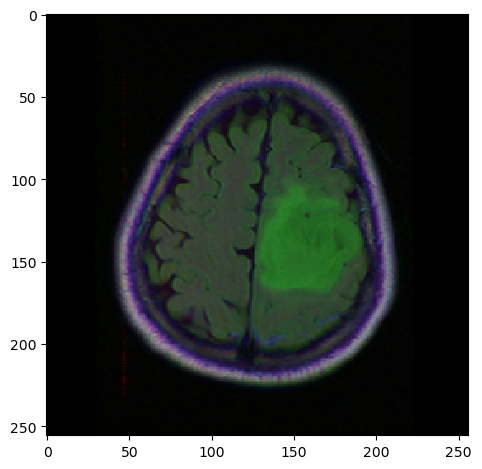

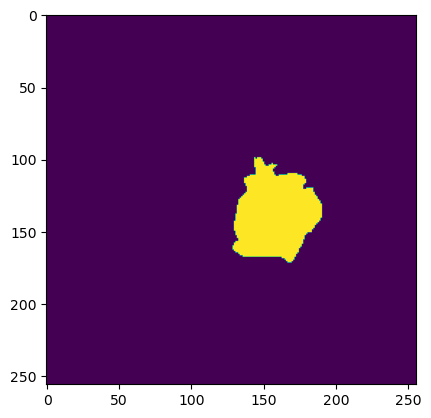

In [9]:
imshow(x[50])
plt.show()
plt.imshow(np.squeeze(y[50]))

In [10]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print(f"X_train.shape: {X_train.shape}\nY_train.shape: {y_train.shape}")

X_train.shape: (3143, 256, 256, 3)
Y_train.shape: (3143, 256, 256, 1)


In [11]:
input = tf.keras.layers.Input((256, 256, 3))

s = tf.keras.layers.Lambda(lambda x: x / 256)(input)

c1 = tf.keras.layers.Conv2D(16, (3, 3), activation="relu", kernel_initializer='he_normal', padding='same')(s)
c1 = tf.keras.layers.Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c1)
c1 = tf.keras.layers.Dropout(0.1)(c1)
c1 = tf.keras.layers.Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c1)
p1 = tf.keras.layers.MaxPooling2D((2, 2))(c1)

c2 = tf.keras.layers.Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p1)
c2 = tf.keras.layers.Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c2)
c2 = tf.keras.layers.Dropout(0.1)(c2)
c2 = tf.keras.layers.Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c2)
p2 = tf.keras.layers.MaxPooling2D((2, 2))(c2)

c3 = tf.keras.layers.Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p2)
c3 = tf.keras.layers.Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c3)
c3  = tf.keras.layers.Dropout(0.2)(c3)
c3 = tf.keras.layers.Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c3)
p3 = tf.keras.layers.MaxPooling2D((2, 2))(c3)

c4 = tf.keras.layers.Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p3)
c4 = tf.keras.layers.Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c4)
c4 = tf.keras.layers.Dropout(0.2)(c4)
c4 = tf.keras.layers.Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c4)
p4 = tf.keras.layers.MaxPooling2D((2, 2))(c4)

c5 = tf.keras.layers.Conv2D(256, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p4)
c5 = tf.keras.layers.Conv2D(256, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c5)
c5 = tf.keras.layers.Dropout(0.3)(c5)
c5 = tf.keras.layers.Conv2D(256, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c5)
p5 = tf.keras.layers.MaxPooling2D((2, 2))(c5)

c6 = tf.keras.layers.Conv2D(512, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p5)
c6 = tf.keras.layers.Conv2D(512, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c6)
c6 = tf.keras.layers.Dropout(0.3)(c6)
c6 = tf.keras.layers.Conv2D(512, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c6)

u7 = tf.keras.layers.Conv2DTranspose(256, (2, 2), strides=(2, 2), padding='same')(c6)
u7 = tf.keras.layers.concatenate([u7, c5])
c7 = tf.keras.layers.Conv2D(256, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u7)
c7 = tf.keras.layers.Conv2D(256, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c7)
c7 = tf.keras.layers.Dropout(0.3)(c7)
c7 = tf.keras.layers.Conv2D(256, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c7)

u8 = tf.keras.layers.Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(c7)
u8 = tf.keras.layers.concatenate([u8, c4])
c8 = tf.keras.layers.Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u8)
c8 = tf.keras.layers.Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c8)
c8 = tf.keras.layers.Dropout(0.2)(c8)
c8 = tf.keras.layers.Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c8)

u9 = tf.keras.layers.Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(c8)
u9 = tf.keras.layers.concatenate([u9, c3])
c9 = tf.keras.layers.Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u9)
c9 = tf.keras.layers.Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c9)
c9 = tf.keras.layers.Dropout(0.2)(c9)
c9 = tf.keras.layers.Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c9)

u10 = tf.keras.layers.Conv2DTranspose(32, (2, 2), strides=(2, 2), padding='same')(c9)
u10 = tf.keras.layers.concatenate([u10, c2])
c10 = tf.keras.layers.Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u10)
c10 = tf.keras.layers.Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c10)
c10 = tf.keras.layers.Dropout(0.1)(c10)
c10 = tf.keras.layers.Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c10)

u11 = tf.keras.layers.Conv2DTranspose(16, (2, 2), strides=(2, 2), padding='same')(c10)
u11 = tf.keras.layers.concatenate([u11, c1])
c11 = tf.keras.layers.Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u11)
c11 = tf.keras.layers.Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c11)
c11 = tf.keras.layers.Dropout(0.1)(c11)
c11 = tf.keras.layers.Conv2D(16, (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c11)

outputs = tf.keras.layers.Conv2D(1, (1, 1), activation='sigmoid')(c11)

model = tf.keras.Model(inputs=input, outputs=outputs, name='U-NET')
mse = tf.keras.losses.MeanSquaredError()
model.compile(optimizer='adam', loss="binary_crossentropy", metrics=['accuracy','iou_coef'])

In [12]:
def iou_coef(y_true, y_pred, smooth=100):
    intersection = K.sum(y_true * y_pred)
    sum = K.sum(y_true + y_pred)
    iou = (intersection + smooth) / (sum - intersection + smooth)
    return iou
from tensorflow.keras import backend as K

def stable_binary_crossentropy(y_true, y_pred):
    y_pred = K.clip(y_pred, K.epsilon(), 1 - K.epsilon())
    return K.binary_crossentropy(y_true, y_pred)
mse = tf.keras.losses.MeanSquaredError()
def dice_loss(pred, target, smooth=1e-6):
    intersection = (pred * target).sum()
    union = pred.sum() + target.sum()
    return 1 - (2.0 * intersection + smooth) / (union + smooth)
model.compile(optimizer='adam', loss="binary_crossentropy", metrics=['accuracy', iou_coef,mse])


In [13]:
checkpoint_path = './training/weight{epoch:04d}.h5'
checkpoint_dir = os.path.dirname(checkpoint_path)
callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                 save_weights_only=True,
                                                 mode='auto', save_freq='epoch',
                                                 monitor='val_loss',
                                                 save_best_only=False,
                                                 verbose=1)

In [14]:
os.environ["CUDA_VISIBLE_DEVICES"]="0"
try:
    gpu = tf.config.list_physical_devices('GPU')
    tf.config.experimental.set_memory_growth(gpu[0], True)
    
    tf.keras.backend.clear_session()
except Exception as e:
    print(e)

Physical devices cannot be modified after being initialized


In [15]:
tf.keras.backend.clear_session()
from tensorflow.keras import mixed_precision
policy = mixed_precision.Policy('mixed_float16')
mixed_precision.set_global_policy(policy)
config = tf.compat.v1.ConfigProto()
config.gpu_options.per_process_gpu_memory_fraction = 0.9
session = tf.compat.v1.Session(config=config)

INFO:tensorflow:Mixed precision compatibility check (mixed_float16): OK
Your GPU will likely run quickly with dtype policy mixed_float16 as it has compute capability of at least 7.0. Your GPU: NVIDIA GeForce RTX 3060, compute capability 8.6


In [16]:
physical_devices = tf.config.experimental.list_physical_devices('GPU')
for device in physical_devices:
    try:
        tf.config.experimental.set_memory_growth(device, True)
    except Exception as e:
        print(e)

Physical devices cannot be modified after being initialized


In [17]:
X_t = X_train.astype('float32')
Y_t = y_train.astype('float32')

In [18]:
print("X_train min/max:", X_t.min(), X_t.max())
print("y_train unique values:", np.unique(Y_t))

X_train min/max: 0.0 255.0
y_train unique values: [0. 1.]


In [19]:
model.fit(X_t, Y_t, validation_split=0.1, batch_size=8, epochs=100 ,callbacks=[callback])

Epoch 1/100
354/354 [==============================] - ETA: 0s - loss: 0.0508 - accuracy: 0.9877 - iou_coef: 0.1244 - mean_squared_error: 0.0119
Epoch 1: saving model to ./training\weight0001.h5
354/354 [==============================] - 48s 118ms/step - loss: 0.0508 - accuracy: 0.9877 - iou_coef: 0.1244 - mean_squared_error: 0.0119 - val_loss: 0.0251 - val_accuracy: 0.9916 - val_iou_coef: 0.2364 - val_mean_squared_error: 0.0063
Epoch 2/100
354/354 [==============================] - ETA: 0s - loss: 0.0263 - accuracy: 0.9922 - iou_coef: 0.2237 - mean_squared_error: 0.0064
Epoch 2: saving model to ./training\weight0002.h5
354/354 [==============================] - 39s 111ms/step - loss: 0.0263 - accuracy: 0.9922 - iou_coef: 0.2237 - mean_squared_error: 0.0064 - val_loss: 0.0262 - val_accuracy: 0.9914 - val_iou_coef: 0.1953 - val_mean_squared_error: 0.0069
Epoch 3/100
354/354 [==============================] - ETA: 0s - loss: 0.0253 - accuracy: 0.9924 - iou_coef: 0.2391 - mean_squared_err

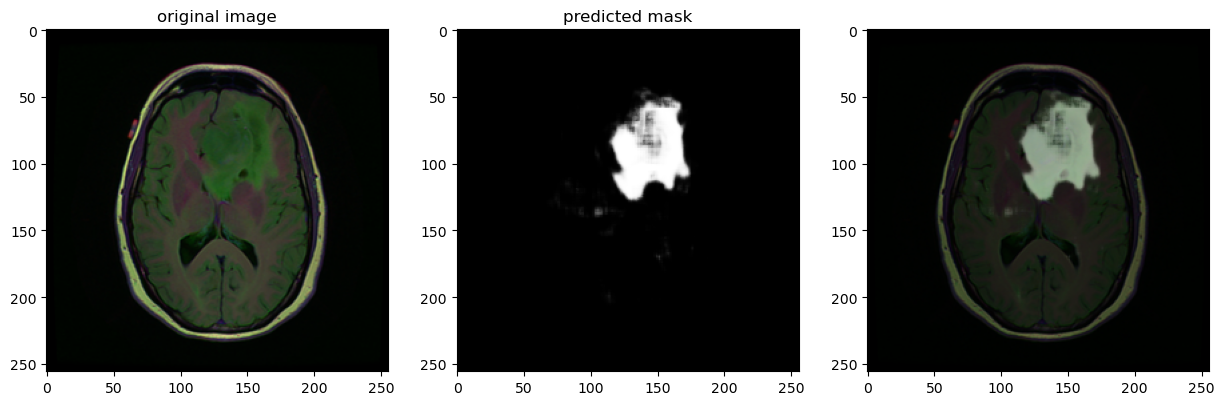

In [64]:
ind = random.randint(0, len(X_test))
img = x[ind]
predictions = model.predict(np.expand_dims(img, axis=0), verbose=0)
plt.figure(figsize=(15, 12))
plt.subplot(1, 3, 1)
plt.title("original image")
plt.imshow(np.squeeze(img))
plt.subplot(1, 3, 2)
plt.title("predicted mask")
plt.imshow(np.squeeze(predictions),cmap="gray")
plt.subplot(1, 3, 3)
plt.imshow(np.squeeze(img))
# plt.imshow(msk,alpha=0.5)
plt.imshow(np.squeeze(predictions), alpha=0.5,cmap="gray")
plt.show()

In [43]:
model.save('model_v2.keras')